# PART 2: Indexing and Evaluation

The search logic lives in `myapp/search/algorithms.py` and the metrics in `myapp/search/evaluation.py`. This notebook runs them on the documents processed in Part 1.

In [1]:
import json, os, re, sys
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append("../..")  # repository root, to import myapp

from myapp.search.algorithms import build_terms, conjunctive_match, create_tfidf_index, search_in_corpus
from myapp.search.evaluation import (avg_precision_at_k, f1_at_k, map_at_k, mrr_at_k, ndcg_at_k,
                                     precision_at_k, recall_at_k, rr_at_k)

PROCESSED_FILE = "../part_1/processed_docs.json"
VALIDATION_FILE = "../../validation_labels.csv"
OUT = "evaluation_output"; os.makedirs(OUT, exist_ok=True)

with open(PROCESSED_FILE, encoding="utf-8") as f:
    docs = json.load(f)
doc_store = {d["pid"]: d for d in docs}
print(len(docs), "documents")

28080 documents


## Part 1: Indexing

### 1.1 Inverted index

The index is built on `all_terms`, the field that Part 1 prepared by merging title, description, brand, categories and product details. Each term stores its postings as `{pid: term frequency}`: the keys are the document list suggested by the statement, and the frequencies are needed for TF-IDF.

Queries are conjunctive (AND): `conjunctive_match` intersects the postings of all query terms, starting with the shortest.

In [2]:
index, idf, doc_norms = create_tfidf_index(docs)
print("Vocabulary size:", len(index))
print("Postings of 'kurta' (first 3):", list(index["kurta"].items())[:3])

terms = build_terms("women cotton kurta")
print("Query terms:", terms)
print("Documents with each term:", {t: len(index[t]) for t in terms})
print("Documents with all terms:", len(conjunctive_match(terms, index)))

Vocabulary size: 6768
Postings of 'kurta' (first 3): [('ETHFYB46QHB6PMYG', 7), ('KTAFTMYM2VYNZACZ', 5), ('ETHFSRVEN6JGSBYG', 4)]
Query terms: ['women', 'cotton', 'kurta']
Documents with each term: {'women': 13807, 'cotton': 19918, 'kurta': 1196}
Documents with all terms: 575


### 1.2 Test queries

The query words were chosen from the popular terms of the collection, keeping only those that describe a product. Very frequent terms such as `cloth` or `color` appear in almost every document, have an idf close to 0, and do not separate products.

In [3]:
popularity = pd.DataFrame({"df": {t: len(p) for t, p in index.items()}})
popularity["cf"] = [sum(index[t].values()) for t in popularity.index]
popularity["idf"] = [round(idf[t], 3) for t in popularity.index]
popularity.sort_values("df", ascending=False).head(15)

,df,cf,idf
cloth,27722,31084,0.019
accessori,27189,29204,0.047
color,26862,37498,0.064
fabric,26450,57370,0.086
pattern,25783,26595,0.123
care,22642,23746,0.311
wear,20971,31691,0.421
wash,20528,26831,0.452
cotton,19918,34079,0.495
suitabl,19309,19507,0.540


In [4]:
product_words = ["cotton", "men", "women", "shirt", "shoe", "run", "polo", "neck", "tshirt", "jacket", "hood",
                 "winter", "kurta", "sneaker", "white"]
popularity.loc[product_words].sort_values("df", ascending=False)

,df,cf,idf
cotton,19918,34079,0.495
shirt,16770,50038,0.744
neck,15190,57363,0.886
men,14250,28248,0.979
women,13807,28041,1.024
white,3937,6626,2.834
polo,3054,11489,3.201
winter,2868,3287,3.291
tshirt,2648,4009,3.407
hood,2161,3600,3.700


In [5]:
TEST_QUERIES = {
    3: "women cotton kurta",
    4: "men running shoes",
    5: "polo neck tshirt men",
    6: "winter hooded jacket men",
    7: "white sneakers women",
}
VALIDATION_QUERIES = {
    1: "women full sleeve sweatshirt cotton",
    2: "men slim jeans blue",
}
ALL_QUERIES = {**VALIDATION_QUERIES, **TEST_QUERIES}

results = {q: search_in_corpus(text, index, idf, doc_norms) for q, text in ALL_QUERIES.items()}
pd.DataFrame([{"query_id": q, "query": ALL_QUERIES[q], "terms": build_terms(ALL_QUERIES[q]), "retrieved": len(results[q])}
              for q in ALL_QUERIES])

,query_id,query,terms,retrieved
0,1,women full sleeve sweatshirt cotton,"[women, full, sleev, sweatshirt, cotton]",500
1,2,men slim jeans blue,"[men, slim, jean, blue]",222
2,3,women cotton kurta,"[women, cotton, kurta]",575
3,4,men running shoes,"[men, run, shoe]",76
4,5,polo neck tshirt men,"[polo, neck, tshirt, men]",203
5,6,winter hooded jacket men,"[winter, hood, jacket, men]",292
6,7,white sneakers women,"[white, sneaker, women]",76


### 1.3 Ranking with TF-IDF

Document and query terms are weighted with $w_{t} = (1 + \log_{2} tf_{t}) \cdot \log_{2}(N / df_t)$, and the score is the cosine similarity between both vectors. Ties are broken by `pid`, so that every run returns the same ranking.

In [6]:
def top_results(query_id, n=10):
    rows = [{"rank": i + 1, "score": round(score, 3), "pid": pid, "title": " ".join(doc_store[pid]["title"].split()),
             "brand": doc_store[pid]["brand"], "selling_price": doc_store[pid]["selling_price"],
             "average_rating": doc_store[pid]["average_rating"]}
            for i, (pid, score) in enumerate(results[query_id][:n])]
    return pd.DataFrame(rows)

for q, text in TEST_QUERIES.items():
    print(f"Query {q}: {text}")
    display(top_results(q))

Query 3: women cotton kurta


,rank,score,pid,title,brand,selling_price,average_rating
0,1,0.522,KTAFAKGUDJEB5DR7,Women Solid Cotton Blend Straight Kurta (Black),Purple Sta,719.0,2.9
1,2,0.505,ETHFPDUMHA2BTSZH,Women Kurta and Pyjama Set Pure Cotton,SATDEVANGIKHADIBHAND,899.0,3.9
2,3,0.505,ETHFPDUMHFZMYHCX,Women Kurta and Pyjama Set Pure Cotton,SATDEVANGIKHADIBHAND,899.0,3.9
3,4,0.505,ETHFPDUMQZ9EZJEH,Women Kurta and Pyjama Set Pure Cotton,SATDEVANGIKHADIBHAND,899.0,3.9
4,5,0.505,ETHFPDUMTE4P2QW9,Women Kurta and Pyjama Set Pure Cotton,SATDEVANGIKHADIBHAND,899.0,3.9
5,6,0.505,ETHFPDUMZXGVUJFT,Women Kurta and Pyjama Set Pure Cotton,SATDEVANGIKHADIBHAND,899.0,3.9
6,7,0.505,ETHFPDUMTGC3VF9M,Women Kurta and Pyjama Set Pure Cotton,SATDEVANGIKHADIBHAND,899.0,3.9
7,8,0.504,ETHFPDUMFNYH3EUX,Women Kurta and Pyjama Set Pure Cotton,SATDEVANGIKHADIBHAND,899.0,3.9
8,9,0.501,ETHFPDUMEWUYJGKR,Women Kurta and Pyjama Set Pure Cotton,SATDEVANGIKHADIBHAND,899.0,3.9
9,10,0.501,ETHFPDUMQAXJKDWZ,Women Kurta and Pyjama Set Pure Cotton,SATDEVANGIKHADIBHAND,899.0,3.9


Query 4: men running shoes


,rank,score,pid,title,brand,selling_price,average_rating
0,1,0.599,SHOEP5GUQYYFKYSN,Running Shoes For Women (White),Vector,990.0,4.1
1,2,0.598,SHOESS9ZEZ6TEQUJ,Running Shoes For Men (Multicolor),Vector,1440.0,4.3
2,3,0.598,SHOESS9ZGMH7CURM,Running Shoes For Men (Multicolor),Vector,1440.0,3.7
3,4,0.438,SHOEWQKVSGFGXPQF,Running Shoes For Men (Blue),Vector,1520.0,3.3
4,5,0.429,SHOEKNRJGEYJCDQK,"SPRINT Running Shoes For Men (Blue, Grey)",Vector,490.0,3.7
5,6,0.428,SHOEKNRJ34UCMAPA,"SPRINT Running Shoes For Men (Black, Grey)",Vector,490.0,3.7
6,7,0.407,SHOFWFVWRSNK5AZJ,Running Shoes For Women (Multicolor),Bone,474.0,3.9
7,8,0.403,SHOEYF5UHUUH5ADZ,"Running Shoes For Women (Blue, Orange)",Vector,990.0,4.3
8,9,0.354,SHOFTZFPNCU4VWHK,Running Shoes For Men (Black),Bone,379.0,4.1
9,10,0.349,SHOFTZFQP8W9G86F,Running Shoes For Women (Black),Bone,341.0,4.1


Query 5: polo neck tshirt men


,rank,score,pid,title,brand,selling_price,average_rating
0,1,0.544,TSHFHTGUQBXMZR6W,Self Design Men Polo Neck Blue T-Shirt,ATHL,322.0,3.8
1,2,0.544,TSHFHTGUWGNGGSRC,Self Design Men Polo Neck Dark Blue T-Shirt,ATHL,322.0,3.8
2,3,0.542,TSHFGQGQZPVZHD2S,Solid Men Polo Neck Black T-Shirt,Pu,719.0,4.1
3,4,0.538,TSHFHTGBHE7HGXKT,Solid Men Polo Neck Yellow T-Shirt,ATHL,322.0,3.3
4,5,0.538,TSHFHTGBXB3ENHWH,Solid Men Polo Neck Yellow T-Shirt,ATHL,322.0,3.3
5,6,0.538,TSHFHTGKJ4R5YZ5H,Color Block Men Polo Neck Green T-Shirt,ATHL,322.0,3.3
6,7,0.537,TSHFHTGGKMW9CUBC,Color Block Men Polo Neck Blue T-Shirt,ATHL,322.0,3.3
7,8,0.533,TSHFHTGKXCZFQV6C,Color Block Men Polo Neck Green T-Shirt,ATHL,322.0,3.3
8,9,0.532,TSHFHTGGHEHSW2VX,Color Block Men Polo Neck Blue T-Shirt,ATHL,322.0,3.3
9,10,0.532,TSHFHTGKR6WZPYK2,Color Block Men Polo Neck Green T-Shirt,ATHL,322.0,3.3


Query 6: winter hooded jacket men


,rank,score,pid,title,brand,selling_price,average_rating
0,1,0.684,JCKFRP3HDZFMAPTW,Full Sleeve Printed Men Jacket,ECKO Unl,1539.0,2.5
1,2,0.683,JCKFRP3HWFS5ZGZM,Full Sleeve Solid Men Jacket,ECKO Unl,1577.0,3.3
2,3,0.682,JCKFRP3GHXH8PTFH,Full Sleeve Solid Men Jacket,ECKO Unl,1799.0,3.7
3,4,0.674,JCKFRP3HTQ977GDH,Full Sleeve Solid Men Jacket,ECKO Unl,1874.0,3.5
4,5,0.664,JCKFRP3GFRQHVDHD,Full Sleeve Solid Men Jacket,ECKO Unl,1847.0,3.4
5,6,0.663,JCKFRP3HKNWD9TRJ,Full Sleeve Solid Men Jacket,ECKO Unl,1986.0,3.8
6,7,0.630,JCKFYQGHVKD6XNCA,Full Sleeve Solid Men Casual Jacket,MASH UNLIMIT,949.0,3.2
7,8,0.620,JCKFMV5XJJQMNASZ,Sleeveless Solid Men Casual Jacket,VOXA,598.0,4.3
8,9,0.614,JCKFRP3GJRQPHNSA,Full Sleeve Solid Men Casual Jacket,ECKO Unl,1516.0,3.7
9,10,0.606,JCKFYQHZAVFQZRYN,Full Sleeve Solid Men Casual Jacket,MASH UNLIMIT,949.0,3.2


Query 7: white sneakers women


,rank,score,pid,title,brand,selling_price,average_rating
0,1,0.342,TSHFYNNX8EWBAFQF,Printed Women Round Neck White T-Shirt,Free Authori,599.0,3.9
1,2,0.307,SHTFMRH8SVHUCHH6,Women Slim Fit Solid Casual Shirt,Solid Styl,699.0,4.0
2,3,0.294,TSHEXH59JKHGZYTM,"Solid Women Round Neck White, Blue T-Shirt",Fairdea,284.0,2.6
3,4,0.262,TSHFDT65DYMCGHNG,Printed Women Round Neck White T-Shirt,REEB,980.0,3.5
4,5,0.260,TSHFW7GFFHQCZZA5,Solid Women Collared Neck White T-Shirt (Pack ...,ModeWa,495.0,5.0
5,6,0.258,TSHFW7GF2JHTWHUZ,"Solid Women Collared Neck White, Blue T-Shirt ...",ModeWa,495.0,3.8
6,7,0.257,TSHFW7GHBZTYWZCZ,"Solid Women Collared Neck White, Black T-Shirt...",ModeWa,495.0,3.8
7,8,0.257,TSHFW7GYGCWUQMCC,"Solid Women Collared Neck White, Black T-Shirt...",ModeWa,495.0,3.8
8,9,0.256,TSHFW7G3JC6HP8FZ,"Solid Women Collared Neck White, Blue T-Shirt ...",ModeWa,495.0,3.8
9,10,0.251,TSHFW7G3RAZ2SSX3,"Solid Women Collared Neck White, Red T-Shirt (...",ModeWa,495.0,3.8


## Part 2: Evaluation

### 2.1 Metrics

The metrics follow the definitions of Practice Session 2. They are checked here on small cases computed by hand.

In [7]:
y_true = np.array([0, 1, 0, 1, 1])
y_score = np.array([0.9, 0.5, 0.6, 0.7, 0.2])   # ranked labels: 0, 1, 0, 1, 1

assert precision_at_k(y_true, y_score, 2) == 1 / 2
assert recall_at_k(y_true, y_score, 2) == 1 / 3
assert np.isclose(f1_at_k(y_true, y_score, 2), 2 * (1 / 2) * (1 / 3) / (1 / 2 + 1 / 3))
assert np.isclose(avg_precision_at_k(y_true, y_score, 5), (1 / 2 + 2 / 4 + 3 / 5) / 3)
assert rr_at_k(y_true, y_score, 5) == 1 / 2
assert rr_at_k(y_true, y_score, 1) == 0
assert ndcg_at_k(y_true, y_true, 5) == 1
assert recall_at_k(y_true, y_score, 5, total_relevant=6) == 1 / 2   # relevant documents not retrieved count
print("Metric checks passed")

Metric checks passed


In [8]:
KS = [5, 10, 20]

def evaluate_query(pids_scores, labels, total_relevant, ideal_labels):
    """Metrics of one ranking. labels: {pid: 0 or 1}. Only judged documents enter the ranking"""
    judged = [(pid, score) for pid, score in pids_scores if pid in labels]
    y_true = np.array([labels[pid] for pid, _ in judged])
    y_score = np.array([score for _, score in judged])
    row = {}
    for k in KS:
        row[f"P@{k}"] = precision_at_k(y_true, y_score, k)
        row[f"R@{k}"] = recall_at_k(y_true, y_score, k, total_relevant)
        row[f"F1@{k}"] = f1_at_k(y_true, y_score, k, total_relevant)
        row[f"AP@{k}"] = avg_precision_at_k(y_true, y_score, k)
        row[f"RR@{k}"] = rr_at_k(y_true, y_score, k)
        row[f"NDCG@{k}"] = ndcg_at_k(y_true, y_score, k, ideal_labels)
    return row, (y_true, y_score)

def evaluate(queries, labels_by_query):
    table, rankings = {}, []
    for q in queries:
        labels = labels_by_query[q]
        table[q], ranking = evaluate_query(results[q], labels, sum(labels.values()), np.array(list(labels.values())))
        rankings.append(ranking)
    table = pd.DataFrame(table).T.rename_axis("query_id")
    summary = pd.DataFrame({k: {"MAP": map_at_k(rankings, k), "MRR": mrr_at_k(rankings, k)} for k in KS}).T.rename_axis("k")
    return table, summary

### 2.2 Validation queries

In [9]:
validation = pd.read_csv(VALIDATION_FILE)
validation_labels = {q: dict(zip(group["pid"], group["labels"])) for q, group in validation.groupby("query_id")}
validation_table, validation_summary = evaluate(VALIDATION_QUERIES, validation_labels)
display(validation_table.round(3).T)
display(validation_summary.round(3))

query_id,1,2
P@5,1.000,0.800
R@5,0.385,0.400
F1@5,0.556,0.533
AP@5,1.000,1.000
RR@5,1.000,1.000
NDCG@5,1.000,0.869
P@10,1.000,0.600
R@10,0.769,0.600
F1@10,0.870,0.600
AP@10,1.000,0.948


,MAP,MRR
k,,
5,1.000,1.0
10,0.974,1.0
20,0.964,1.0


### 2.3 Expert judgments for the test queries

Each query is turned into an explicit information need, applied to **every document of the collection**, so that the relevant documents the AND filter misses also count for Recall. The rules use the title and the structured `product_details`, which describe the product itself. The description is not used, because it often mentions other products.

The top 20 results of each query were also read one by one to confirm the rule.

In [10]:
def details(doc):
    flat = {}
    for item in doc["product_details"] or []:
        flat.update(item)
    return flat

def has(pattern, text):
    return re.search(pattern, text or "", re.IGNORECASE) is not None

def clean_title(doc):
    return " ".join(doc["title"].split())

RELEVANCE_RULES = {
    # a women's kurta (alone or in a set) whose fabric is cotton
    3: lambda d: has(r"\bwomen\b", d["title"]) and has(r"\bkurta\b", d["title"]) and has("cotton", details(d).get("Fabric")),
    # running shoes made for men, not for women
    4: lambda d: has(r"running shoes", d["title"]) and has(r"\bfor men\b", d["title"]),
    # a men's T-shirt with polo neck, however the word "T-shirt" is written
    5: lambda d: has(r"\bmen\b.*polo neck.*t-shirt", clean_title(d)),
    # a men's jacket for winter that really has a hood
    6: lambda d: has(r"\bmen\b", d["title"]) and has(r"\bjacket\b", d["title"]) and d["sub_category"] == "Winter Wear"
                 and details(d).get("Hooded") == "Yes",
    # women's sneakers in white
    7: lambda d: has(r"sneakers for women", clean_title(d)) and has("white", details(d).get("Color")),
}

judged_rows = []
for q in TEST_QUERIES:
    relevant = {d["pid"] for d in docs if RELEVANCE_RULES[q](d)}
    top_20 = {pid for pid, _ in results[q][:20]}
    judged_rows += [{"title": clean_title(doc_store[pid]), "pid": pid, "query_id": q, "labels": int(pid in relevant)}
                    for pid in sorted(relevant | top_20)]

test_labels = pd.DataFrame(judged_rows)
test_labels.to_csv("test_labels.csv", index=False)   # same format as validation_labels.csv

test_labels_by_query = {}
for q in TEST_QUERIES:
    relevant = set(test_labels[(test_labels["query_id"] == q) & (test_labels["labels"] == 1)]["pid"])
    test_labels_by_query[q] = {pid: int(pid in relevant) for pid, _ in results[q]} | {pid: 1 for pid in relevant}

pd.DataFrame([{"query_id": q, "query": TEST_QUERIES[q], "retrieved": len(results[q]),
               "relevant in corpus": sum(labels.values()),
               "relevant retrieved": sum(labels[pid] for pid, _ in results[q]),
               "relevant in top 20": sum(labels[pid] for pid, _ in results[q][:20])}
              for q, labels in test_labels_by_query.items()])

,query_id,query,retrieved,relevant in corpus,relevant retrieved,relevant in top 20
0,3,women cotton kurta,575,322,322,20
1,4,men running shoes,76,23,23,10
2,5,polo neck tshirt men,203,1326,186,20
3,6,winter hooded jacket men,292,49,49,4
4,7,white sneakers women,76,3,3,0


In [11]:
test_table, test_summary = evaluate(TEST_QUERIES, test_labels_by_query)
display(test_table.round(3).T)
display(test_summary.round(3))

query_id,3,4,5,6,7
P@5,1.000,0.800,1.000,0.000,0.0
R@5,0.016,0.174,0.004,0.000,0.0
F1@5,0.031,0.286,0.008,0.000,0.0
AP@5,1.000,0.679,1.000,0.000,0.0
RR@5,1.000,0.500,1.000,0.000,0.0
NDCG@5,1.000,0.661,1.000,0.000,0.0
P@10,1.000,0.600,1.000,0.100,0.0
R@10,0.031,0.261,0.008,0.020,0.0
F1@10,0.060,0.364,0.015,0.034,0.0
AP@10,1.000,0.703,1.000,0.100,0.0


,MAP,MRR
k,,
5,0.536,0.50
10,0.561,0.52
20,0.562,0.52


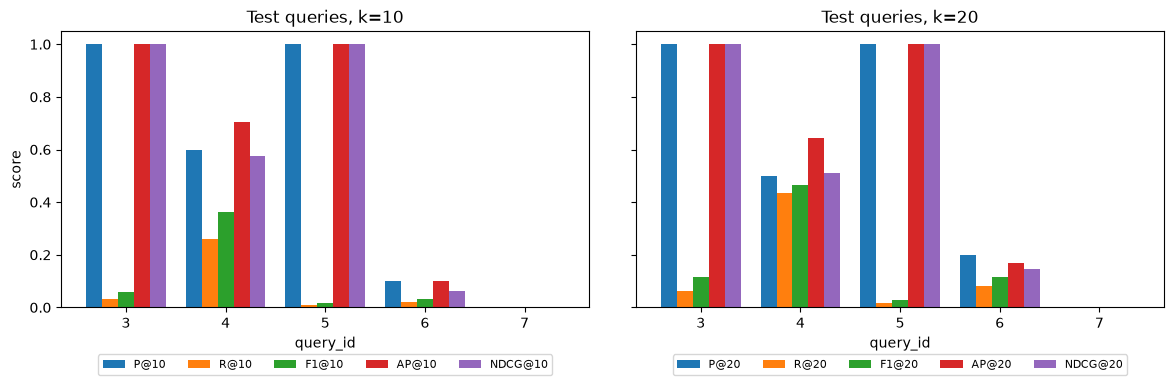

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, k in zip(axes, [10, 20]):
    cols = [f"P@{k}", f"R@{k}", f"F1@{k}", f"AP@{k}", f"NDCG@{k}"]
    test_table[cols].plot(kind="bar", ax=ax, width=0.8)
    ax.set_title(f"Test queries, k={k}"); ax.set_ylabel("score"); ax.set_xlabel("query_id"); ax.set_ylim(0, 1.05)
    ax.tick_params(axis="x", rotation=0); ax.legend(fontsize=8, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.15))
plt.tight_layout(); plt.savefig(f"{OUT}/test_metrics.png", dpi=150); plt.show()

In [13]:
# Evidence for the analysis below
def share(pids, condition):
    pids = list(pids)
    return sum(condition(doc_store[p]) for p in pids), len(pids)

print("Q4 retrieved documents for women:", share([p for p, _ in results[4]], lambda d: has(r"for women", d["title"])))
print("Q4 top 20 for women:", share([p for p, _ in results[4][:20]], lambda d: has(r"for women", d["title"])))
print("Q4 retrieved that are not shoes:", share([p for p, _ in results[4]], lambda d: not has(r"shoes", d["title"])))
print("Q6 retrieved with Hooded = No:", share([p for p, _ in results[6]], lambda d: details(d).get("Hooded") == "No"))
print("Q6 retrieved with Hooded = Yes:", share([p for p, _ in results[6]], lambda d: details(d).get("Hooded") == "Yes"))
print("Q6 top 20 with Hooded = No:", share([p for p, _ in results[6][:20]], lambda d: details(d).get("Hooded") == "No"))
polo_relevant = [p for p, l in test_labels_by_query[5].items() if l]
polo_retrieved = {p for p, _ in results[5]}
print("Q5 relevant, not retrieved:", sum(p not in polo_retrieved for p in polo_relevant), "of", len(polo_relevant))
print("Documents with T-Shirt in the title:", sum(has(r"t-shirt", d["title"]) for d in docs), "| with term 'tshirt':", len(index["tshirt"]))
print("Terms of 't-shirt':", build_terms("t-shirt"), "| 'tshirt':", build_terms("tshirt"), "| 'hoodie':", build_terms("hoodie"), "| 'hooded':", build_terms("hooded"))

print("\nDifferent (title, brand) in the top 20:")
for q in TEST_QUERIES:
    print(" ", q, len({(clean_title(doc_store[p]), doc_store[p]["brand"]) for p, _ in results[q][:20]}))

print("\nEmpty description, corpus:", round(np.mean([not d["description"] for d in docs]), 3))
print("Empty description, top 20 of the test queries:",
      round(np.mean([not doc_store[p]["description"] for q in TEST_QUERIES for p, _ in results[q][:20]]), 3))
print("Out of stock in the top 20 of the test queries:", sum(doc_store[p]["out_of_stock"] for q in TEST_QUERIES for p, _ in results[q][:20]))
print("Distinct scores in the top 20:", {q: len({round(s, 6) for _, s in results[q][:20]}) for q in TEST_QUERIES})

print("\nValidation documents:")
for q in VALIDATION_QUERIES:
    ranks = {p: i + 1 for i, (p, _) in enumerate(results[q])}
    labelled = validation_labels[q]
    found = [ranks[p] for p in labelled if p in ranks]
    print(f"  Q{q}: judged {len(labelled)}, retrieved {len(found)}, relevant not retrieved "
          f"{sum(l for p, l in labelled.items() if p not in ranks)}, engine ranks {min(found)} to {max(found)} of {len(ranks)}")
missing = validation[(validation["query_id"] == 2) & (validation["labels"] == 1) & (~validation["pid"].isin([p for p, _ in results[2]]))]
print(missing[["title", "pid"]].to_string(index=False))

print("\nCategory terms of the first Q4 result:", doc_store[results[4][0][0]]["category_terms"], "|", clean_title(doc_store[results[4][0][0]]))
ranks_7 = {p: i + 1 for i, (p, _) in enumerate(results[7])}
print("Q7 ranks of the relevant documents:", sorted(ranks_7[p] for p, l in test_labels_by_query[7].items() if l))
print("Q7 top 20 with 'sneaker' in the title:", share([p for p, _ in results[7][:20]], lambda d: has("sneaker", d["title"])))
print("Q7 retrieved with 'sneaker' in the title:", share([p for p, _ in results[7]], lambda d: has("sneaker", d["title"])))
for pid in missing["pid"]:
    print(pid, "| url:", doc_store[pid]["url"].split("/p/")[0].split("/")[-1], "| Ideal For:", details(doc_store[pid]).get("Ideal For"))
slug = lambda d: d["url"].split("/p/")[0].split("/")[-1]
print("Title says women, url says men:", sum(has(r"\bwomen\b", d["title"]) and has(r"-men-", slug(d)) and not has("women", slug(d)) for d in docs))
print("Title says men, url says women:", sum(has(r"\bmen\b", d["title"]) and has(r"women", slug(d)) for d in docs))
for term in ["run", "shoe", "sneaker", "white", "women"]:
    print(term, "idf", round(idf[term], 3))

Q4 retrieved documents for women: (39, 76)
Q4 top 20 for women: (9, 20)
Q4 retrieved that are not shoes: (23, 76)
Q6 retrieved with Hooded = No: (181, 292)
Q6 retrieved with Hooded = Yes: (68, 292)
Q6 top 20 with Hooded = No: (16, 20)
Q5 relevant, not retrieved: 1140 of 1326
Documents with T-Shirt in the title: 12247 | with term 'tshirt': 2648
Terms of 't-shirt': ['shirt'] | 'tshirt': ['tshirt'] | 'hoodie': ['hoodi'] | 'hooded': ['hood']

Different (title, brand) in the top 20:
  3 2
  4 18
  5 13
  6 9
  7 15

Empty description, corpus: 0.397
Empty description, top 20 of the test queries: 0.42
Out of stock in the top 20 of the test queries: 8
Distinct scores in the top 20: {3: 7, 4: 19, 5: 18, 6: 19, 7: 17}

Validation documents:
  Q1: judged 20, retrieved 20, relevant not retrieved 0, engine ranks 149 to 500 of 500
  Q2: judged 20, retrieved 8, relevant not retrieved 4, engine ranks 5 to 175 of 222
                        title              pid
        Slim Women Blue Jeans JEAF8CHSV

### 2.4 Comments on the metrics

The two evaluations differ in what enters the ranking. For the validation queries only the 40 judged documents are ranked, because `validation_labels.csv` says nothing about the others. For the test queries the whole result list is judged. The numbers of both groups cannot be compared directly.

| Metric | What it tells us | What it ignores |
|---|---|---|
| **P@K** | Share of the first K results that are relevant, which is what a user sees on the first page. | The order inside the top K, and the relevant documents outside it. It also divides by K when fewer than K documents exist. |
| **R@K** | Share of all relevant documents found in the top K. | The order. Its maximum is K/R, so it is low when many documents are relevant. |
| **F1@K** | Harmonic mean of P@K and R@K. It is only high when both are high. | The order. It inherits the limit of R@K. |
| **AP@K** | Rewards relevant documents placed early, for one query. | Here it follows the Practice Session 2 definition and divides by the relevant documents found in the top K, so relevant documents never retrieved do not lower it. |
| **MAP** | Mean AP over the queries, a single number for ranking quality. | Differences between queries: a very good query can hide a very bad one. |
| **RR / MRR** | How early the first relevant document appears. Useful when one good answer is enough. | Everything after that first document. |
| **NDCG@K** | Compares the ranking with the ideal one, with a logarithmic discount by position. It is built for graded relevance; with our binary labels each relevant document has the same gain. | With binary labels it cannot tell a perfect match from a partial one. |

**Validation.** Query 1 reaches P@10 = 1.000 and R@20 = 1.000: the first 10 results are relevant, and the 13 relevant documents are almost entirely ahead of the 7 non-relevant ones (AP@20 = 0.980). This looks excellent, but all 20 judged documents appear between ranks 149 and 500 of the full result list, so the first page of the engine shows documents nobody judged. The score only says that the judged documents are ordered well among themselves.

Query 2 shows why several metrics are needed. AP@10 = 0.948 and RR = 1.000 suggest a nearly perfect system, while R@20 = 0.600 and NDCG@20 = 0.716 show that 4 of the 10 relevant documents were never retrieved. AP cannot see those 4 documents with this definition, and NDCG can, because its ideal ranking contains all 10. Only 8 of the 20 judged documents pass the AND filter, which also explains why P@20 falls to 0.300.

**Test queries.** MAP@10 = 0.561 and MRR@10 = 0.520 are averages of very different behaviours:

- **Queries 3 and 5 (P@20 = 1.000).** These look solved, but R@20 is only 0.062 and 0.015. This is not a ranking failure, since 322 and 1326 documents are relevant and the maximum R@20 is 20/322 = 0.062 and 20/1326 = 0.015. The real problem is in Query 5: only 186 of the 1326 relevant documents are retrieved at all (14%).
- **Query 4 (P@10 = 0.600, RR = 0.500).** The first result is a shoe for women, so RR drops to 0.500. All 23 relevant documents are retrieved, but only 10 reach the top 20.
- **Query 6 (P@10 = 0.100, RR = 0.100).** All 49 relevant documents are retrieved, yet the first one appears at rank 10. The filter is fine and the ranking is poor.
- **Query 7 (all metrics at 0 up to k = 20).** The 3 relevant documents are at ranks 22, 52 and 58 of 76. None of the top 20 results has "sneaker" in its title. NDCG, AP and RR are all 0 because K is too short to reach them. A larger K would hide how bad this ranking is for a user.

MAP and MRR therefore summarise a system that works well on two queries and fails on the other three.

### 2.5 Problems of the current system and proposed solutions

1. **All fields weigh the same (ranking quality, field types).** A term in the title counts like a term in a description. In Query 7, T-shirts and socks whose description mentions sneakers beat the 3 real white sneakers. Of the 76 retrieved documents, only 3 have "sneaker" in the title and none is in the top 20. *Solution:* index the fields separately and use a weighted score such as BM25F, giving more weight to title and product type.

2. **Field names and values are indexed as plain words (field types, indexing).** `details_text` writes "Hooded No" into the document, so the term `hood` also matches jackets without a hood. In Query 6, 181 of the 292 retrieved documents have `Hooded = No`, against 68 with `Hooded = Yes`, and 16 of the top 20 have no hood. *Solution:* keep attributes such as `Hooded` as structured filters instead of text, and extract them from the query ("hooded" becomes `Hooded = Yes`).

3. **The category adds a false gender term (retrieval accuracy).** The sub-category "Men's Footwear" contains women's shoes too, so `men` is added to all of them. In Query 4, 39 of the 76 retrieved documents and 9 of the top 20 are for women, including the first result. *Solution:* detect gender in the query and filter by `Ideal For`, or stop indexing the sub-category text for these documents.

4. **The tokenizer breaks "T-Shirt" (pre-processing, query formulation).** `t-shirt` becomes `shirt`, because the single letter is dropped, while `tshirt` stays as another term. 12247 documents have "T-Shirt" in the title, but only 2648 contain `tshirt`. In Query 5, 1140 of the 1326 relevant documents are lost, and "t-shirt" as a query would also match ordinary shirts. `hooded` and `hoodie` also become different terms, `hood` and `hoodi`. *Solution:* normalise compound words before tokenizing (`t-shirt` and `tshirt` to one term), and add a synonym dictionary for the domain, applied to the query or at indexing time.

5. **The AND filter is too strict (retrieval accuracy, query formulation).** One missing word removes a document. In Query 2, 4 of the 10 relevant documents disappear this way. *Solution:* keep AND as a first pass and fall back to a soft match when there are few results, for example requiring a minimum share of query terms or using an OR ranking where matching more terms scores higher.

6. **Titles and URLs disagree on gender (data quality).** In 12764 documents the title says "Women" while the product URL says "men", for example `JEAF8CHSVCP5GUH9`, titled "Slim Women Blue Jeans" with the URL `gas-slim-men-blue-jeans`. That document is labelled relevant for "men slim jeans blue" but is not retrieved. Our judgments rely on the title and `Ideal For`, so they inherit this noise. *Solution:* check where the gender value comes from, and compare title, `Ideal For` and URL during pre-processing to flag contradictions.

7. **Near-duplicates fill the first page (ranking quality).** In Query 3 the top 20 contain only 2 different products (same title and brand), mostly "Women Kurta and Pyjama Set Pure Cotton" in different colours, with only 7 different scores. P@20 = 1.000 hides that the user sees one product 20 times. *Solution:* group colour variants of a product, or diversify the results (for example with Maximal Marginal Relevance).

8. **The score only uses the text (ranking quality).** Rating, price and stock are not part of the score: 8 of the 100 top-20 results of the test queries are out of stock. *Solution:* remove or demote out-of-stock products, and combine the text score with the rating in a final score, or learn the combination with Learning to Rank.

9. **The evaluation has its own limits.** The validation sample only judges 40 documents, far from the first results of the engine, and its labels differ between documents with identical titles. Our own labels depend on explicit rules, on five queries, and they are binary. *Solution:* judge the top results of the engine for each new version, use more queries, and use graded relevance so that NDCG can show its full value.
